# Лабораторная работа
## Классификация рукописных цифр методом k ближайших соседей

**Цель работы:** изучить алгоритм k ближайших соседей (KNN) и применить его для классификации изображений рукописных цифр.

### Задачи работы

1. Загрузить и исследовать набор данных рукописных цифр.
2. Реализовать алгоритм KNN самостоятельно.
3. Разделить данные на обучающую, валидационную и тестовую выборки.
4. Исследовать влияние количества соседей на точность классификации.
5. Подобрать оптимальное значение параметра k.
6. Оценить качество классификации на тестовых данных.
7. Построить матрицу ошибок и визуализировать результаты.
8. Сравнить собственную реализацию KNN с реализацией из Scikit-learn.

## 1. Теоретические сведения

### Метод k ближайших соседей (KNN)

Метод k ближайших соседей (K-Nearest Neighbors) — алгоритм машинного обучения с учителем, применяемый для классификации и регрессии.

Основная идея алгоритма заключается в том, что объекты, близкие друг к другу в пространстве признаков, с высокой вероятностью принадлежат одному классу.

Для классификации нового объекта алгоритм выполняет следующие действия:

1. Вычисляет расстояния от нового объекта до всех объектов обучающей выборки.
2. Находит k объектов с наименьшими расстояниями.
3. Определяет наиболее часто встречающийся класс среди найденных соседей.
4. Присваивает новому объекту этот класс.

### Евклидово расстояние

Для определения близости объектов используется евклидово расстояние:

$$
d(x,z)=\sqrt{\sum_{i=1}^{n}(x_i-z_i)^2}
$$

где:

- $x$ — классифицируемый объект;
- $z$ — объект обучающей выборки;
- $n$ — количество признаков;
- $x_i,z_i$ — значения соответствующих признаков.

### Особенности KNN

- Алгоритм не требует обучения параметров модели.
- Классификация выполняется на основе сохранённых обучающих данных.
- Качество классификации зависит от количества соседей k.
- При малом k модель может быть чувствительна к шуму.
- При большом k модель может недостаточно учитывать локальные особенности данных.

### 2. Загрузка и исследование данных

In [1]:
#Импорт библиотек
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

plt.rcParams["figure.figsize"] = (10, 6)

print("Библиотеки успешно импортированы")

Библиотеки успешно импортированы


In [2]:
#Загрузка набора данных
digits = load_digits()

X = digits.data
y = digits.target

print("Размерность массива признаков:", X.shape)
print("Размерность массива меток:", y.shape)

print("Количество изображений:", len(X))
print("Количество признаков:", X.shape[1])

print("Доступные классы:", np.unique(y))

print("Минимальное значение пикселя:", X.min())
print("Максимальное значение пикселя:", X.max())

Размерность массива признаков: (1797, 64)
Размерность массива меток: (1797,)
Количество изображений: 1797
Количество признаков: 64
Доступные классы: [0 1 2 3 4 5 6 7 8 9]
Минимальное значение пикселя: 0.0
Максимальное значение пикселя: 16.0


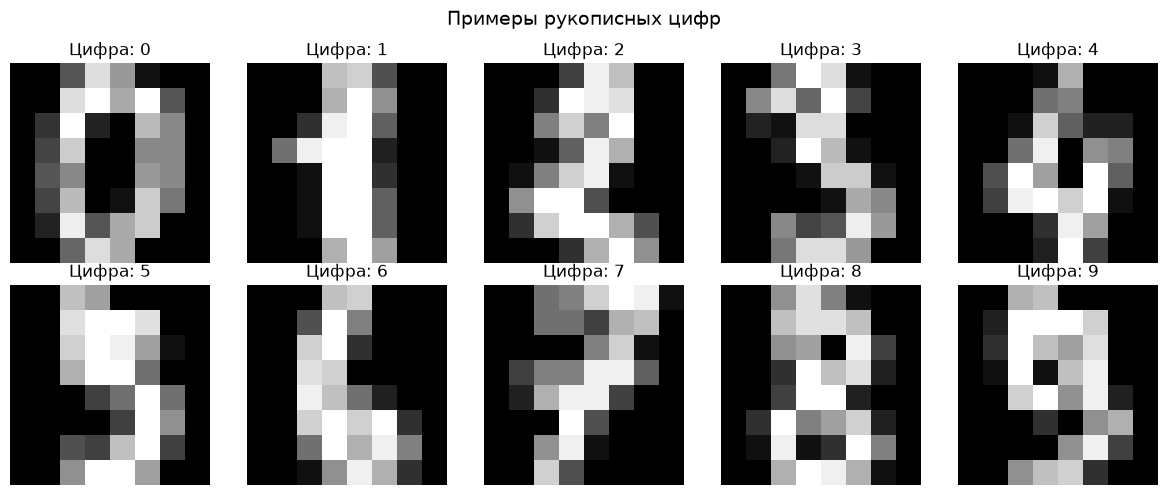

In [3]:
#Визуализация изображений
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray")

    ax.set_title(f"Цифра: {y[i]}")
    ax.axis("off")

plt.suptitle("Примеры рукописных цифр", fontsize=14)

plt.tight_layout()
plt.show()

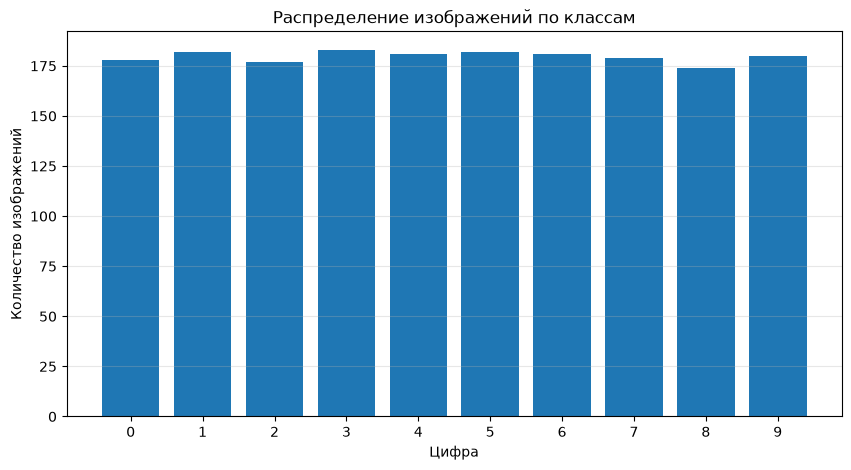

Цифра 0: 178 изображений
Цифра 1: 182 изображений
Цифра 2: 177 изображений
Цифра 3: 183 изображений
Цифра 4: 181 изображений
Цифра 5: 182 изображений
Цифра 6: 181 изображений
Цифра 7: 179 изображений
Цифра 8: 174 изображений
Цифра 9: 180 изображений


In [4]:
#Распределение изображений по классам
classes, counts = np.unique(y, return_counts=True)

plt.figure(figsize=(10, 5))

plt.bar(classes, counts)

plt.xlabel("Цифра")
plt.ylabel("Количество изображений")

plt.title("Распределение изображений по классам")

plt.xticks(range(10))
plt.grid(axis="y", alpha=0.3)

plt.show()

for digit, count in zip(classes, counts):
    print(f"Цифра {digit}: {count} изображений")

### 3. Подготовка данных

In [5]:
#Разделение данных на выборки
# Отделяем 20% данных для тестирования

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Оставшиеся 80% разделяем на обучение и валидацию

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.2,
    random_state=42,
    stratify=y_train_val
)

print("Обучающая выборка:", X_train.shape)
print("Валидационная выборка:", X_val.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (1149, 64)
Валидационная выборка: (288, 64)
Тестовая выборка: (360, 64)


### 4. Собственная реализация KNN

In [6]:
class MyKNN:

    def __init__(self, k=3):
        self.k = k

    def fit(self, X_train, y_train):
        """
        Сохранение обучающих данных.
        """

        if self.k < 1 or self.k > len(X_train):
            raise ValueError("Некорректное количество соседей")

        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)

    def euclidean_distance(self, x1, x2):
        """
        Вычисление евклидова расстояния.
        """

        return np.sqrt(np.sum((x1 - x2) ** 2))

    def predict_one(self, x):
        """
        Предсказание класса одного изображения.
        """

        # Вычисляем расстояния до всех обучающих объектов
        distances = np.array([
            self.euclidean_distance(x, x_train)
            for x_train in self.X_train
        ])

        # Находим индексы k ближайших соседей
        nearest_indices = np.argsort(distances)[:self.k]

        # Получаем классы ближайших соседей
        nearest_labels = self.y_train[nearest_indices]

        # Подсчитываем количество объектов каждого класса
        labels, counts = np.unique(
            nearest_labels,
            return_counts=True
        )

        # Выбираем наиболее часто встречающийся класс
        predicted_class = labels[np.argmax(counts)]

        return predicted_class

    def predict(self, X):
        """
        Предсказание классов нескольких изображений.
        """

        predictions = [
            self.predict_one(x)
            for x in X
        ]

        return np.array(predictions)

In [7]:
# Проверка собственного алгоритма
my_knn = MyKNN(k=3)

my_knn.fit(X_train, y_train)

# Проверяем модель на первых 10 изображениях
predictions = my_knn.predict(X_val[:10])

print("Настоящие цифры:")
print(y_val[:10])

print("\nПредсказанные цифры:")
print(predictions)

print("\nКоличество правильных ответов:")
print(np.sum(predictions == y_val[:10]), "из 10")

Настоящие цифры:
[8 0 5 7 4 9 7 1 0 0]

Предсказанные цифры:
[8 0 5 7 4 9 7 1 0 0]

Количество правильных ответов:
10 из 10


### 5. Подбор оптимального количества соседей

In [8]:
k_values = range(1, 16)

val_accuracies = []

for k in k_values:

    model = MyKNN(k=k)

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)

    val_accuracies.append(accuracy)

    print(f"k = {k:2d} | Accuracy = {accuracy:.4f}")

k =  1 | Accuracy = 0.9826
k =  2 | Accuracy = 0.9861
k =  3 | Accuracy = 0.9826
k =  4 | Accuracy = 0.9792
k =  5 | Accuracy = 0.9792
k =  6 | Accuracy = 0.9722
k =  7 | Accuracy = 0.9792
k =  8 | Accuracy = 0.9722
k =  9 | Accuracy = 0.9757
k = 10 | Accuracy = 0.9757
k = 11 | Accuracy = 0.9722
k = 12 | Accuracy = 0.9757
k = 13 | Accuracy = 0.9757
k = 14 | Accuracy = 0.9757
k = 15 | Accuracy = 0.9757


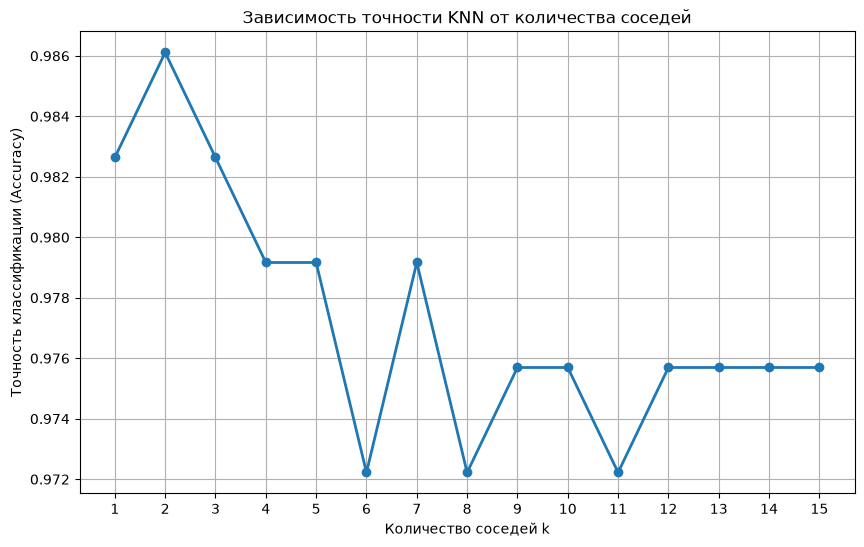

In [9]:
# График зависимости точности от K
plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    val_accuracies,
    marker="o",
    linewidth=2
)

plt.xlabel("Количество соседей k")
plt.ylabel("Точность классификации (Accuracy)")

plt.title("Зависимость точности KNN от количества соседей")

plt.xticks(list(k_values))

plt.grid(True)

plt.show()

In [10]:
# Определение оптимального k
best_index = np.argmax(val_accuracies)

best_k = list(k_values)[best_index]

best_accuracy = val_accuracies[best_index]

print("Оптимальное количество соседей:", best_k)

print(
    f"Максимальная точность на валидации: "
    f"{best_accuracy * 100:.2f}%"
)

Оптимальное количество соседей: 2
Максимальная точность на валидации: 98.61%


### 6. Обучение итоговой модели

In [11]:
# Создание итогового классификатора
final_model = MyKNN(k=best_k)

final_model.fit(X_train_val, y_train_val)

print("Итоговая модель создана")
print("Количество соседей:", best_k)
print("Количество обучающих изображений:", len(X_train_val))

Итоговая модель создана
Количество соседей: 2
Количество обучающих изображений: 1437


In [12]:
#Оценка точности классификации
y_pred = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

print("Результаты классификации:")

print(f"Accuracy: {test_accuracy:.4f}")

print(f"Точность в процентах: {test_accuracy * 100:.2f}%")

print("Количество тестовых изображений:", len(y_test))

print("Количество правильных ответов:", np.sum(y_pred == y_test))

print("Количество ошибок:", np.sum(y_pred != y_test))

Результаты классификации:
Accuracy: 0.9861
Точность в процентах: 98.61%
Количество тестовых изображений: 360
Количество правильных ответов: 355
Количество ошибок: 5


In [13]:
#Дополнительные метрики классификации
print("Отчёт о качестве классификации:\n")

print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

Отчёт о качестве классификации:

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9231    1.0000    0.9600        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    1.0000    1.0000        37
           4     0.9730    1.0000    0.9863        36
           5     1.0000    1.0000    1.0000        37
           6     1.0000    1.0000    1.0000        36
           7     1.0000    1.0000    1.0000        36
           8     0.9697    0.9143    0.9412        35
           9     1.0000    0.9444    0.9714        36

    accuracy                         0.9861       360
   macro avg     0.9866    0.9859    0.9859       360
weighted avg     0.9867    0.9861    0.9861       360



### 7. Анализ результатов

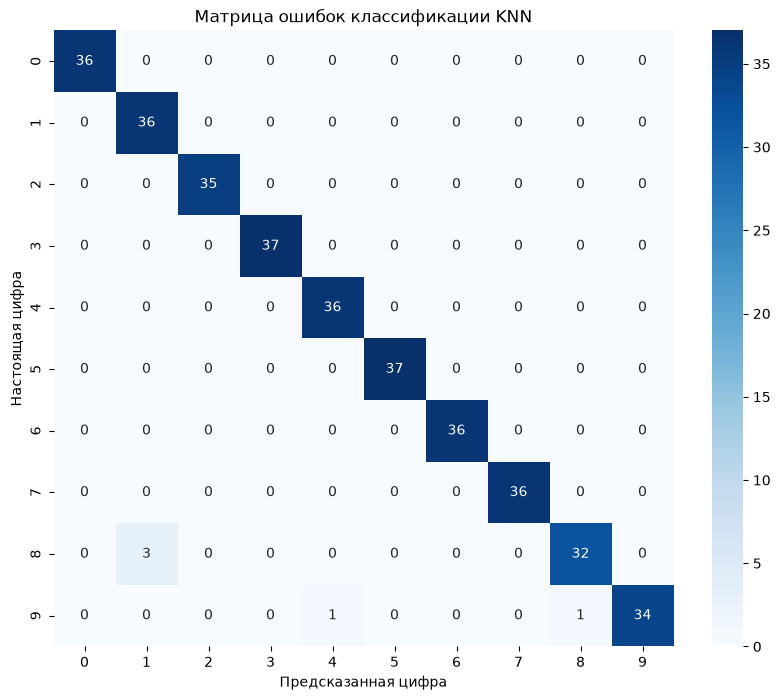

In [14]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Предсказанная цифра")
plt.ylabel("Настоящая цифра")

plt.title("Матрица ошибок классификации KNN")

plt.show()

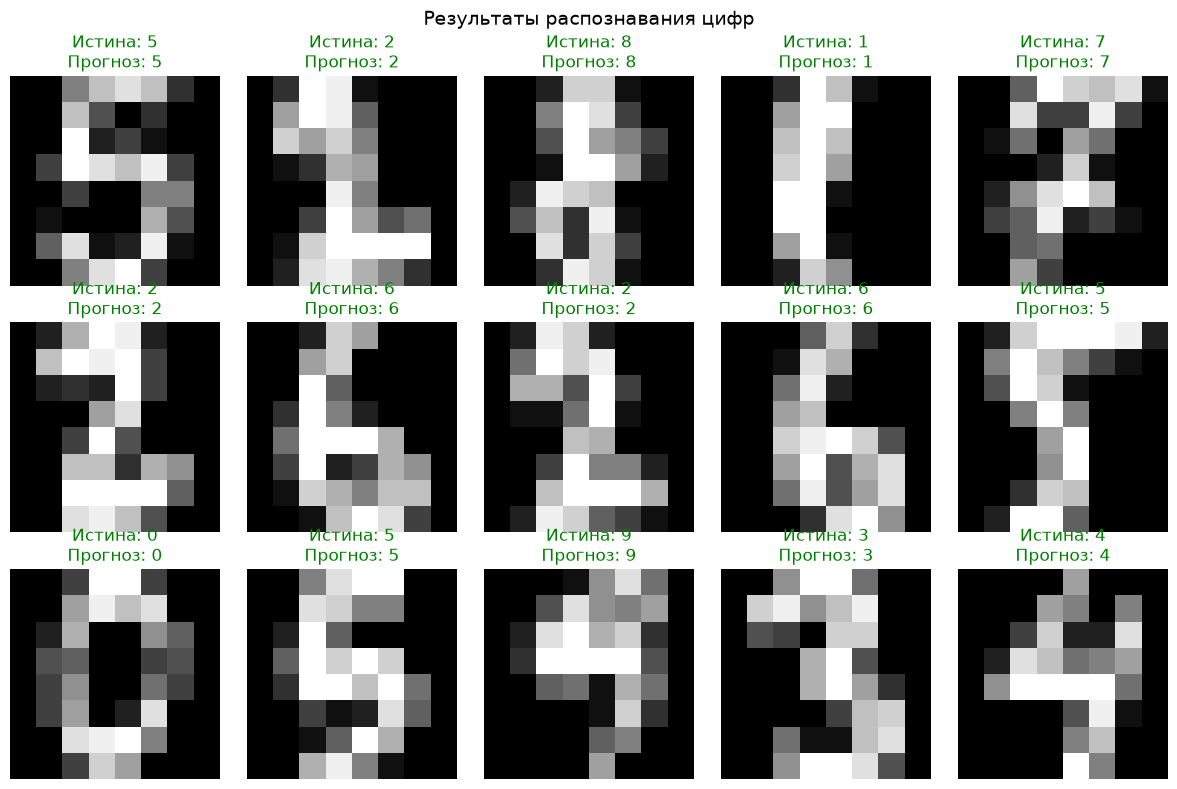

In [15]:
#Визуализация предсказаний
fig, axes = plt.subplots(3, 5, figsize=(12, 8))

for i, ax in enumerate(axes.flat):

    image = X_test[i].reshape(8, 8)

    true_label = y_test[i]
    predicted_label = y_pred[i]

    ax.imshow(image, cmap="gray")

    color = (
        "green"
        if true_label == predicted_label
        else "red"
    )

    ax.set_title(
        f"Истина: {true_label}\n"
        f"Прогноз: {predicted_label}",
        color=color
    )

    ax.axis("off")

plt.suptitle("Результаты распознавания цифр", fontsize=14)

plt.tight_layout()
plt.show()

Всего ошибок: 5


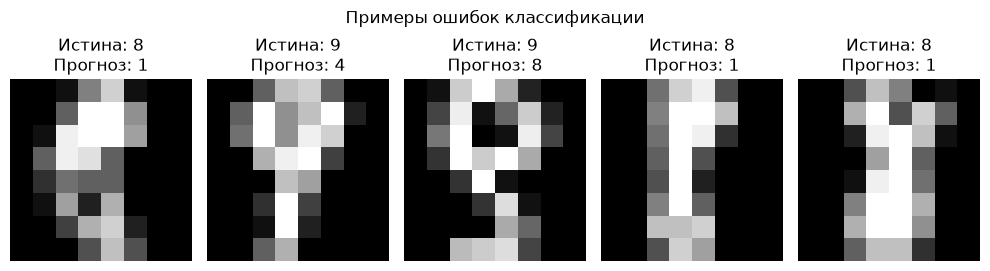

In [16]:
#Анализ ошибочных предсказаний
error_indices = np.where(y_test != y_pred)[0]

print("Всего ошибок:", len(error_indices))

if len(error_indices) > 0:

    n = min(10, len(error_indices))

    fig, axes = plt.subplots(
        1,
        n,
        figsize=(2 * n, 3)
    )

    axes = np.atleast_1d(axes)

    for i in range(n):

        index = error_indices[i]

        image = X_test[index].reshape(8, 8)

        axes[i].imshow(image, cmap="gray")

        axes[i].set_title(
            f"Истина: {y_test[index]}\n"
            f"Прогноз: {y_pred[index]}"
        )

        axes[i].axis("off")

    plt.suptitle("Примеры ошибок классификации")

    plt.tight_layout()
    plt.show()

else:

    print("Модель правильно распознала все изображения!")

### 8. Сравнение с готовой реализацией KNN

In [17]:
sklearn_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    metric="euclidean",
    weights="uniform",
    algorithm="brute"
)

sklearn_knn.fit(X_train_val, y_train_val)

sklearn_pred = sklearn_knn.predict(X_test)

sklearn_accuracy = accuracy_score(
    y_test,
    sklearn_pred
)

print("Сравнение реализаций:\n")

print(
    f"Собственный KNN: {test_accuracy * 100:.2f}%"
)

print(
    f"Scikit-learn KNN: {sklearn_accuracy * 100:.2f}%"
)

print(
    "Совпадение предсказаний:",
    np.mean(y_pred == sklearn_pred) * 100,
    "%"
)

Сравнение реализаций:

Собственный KNN: 98.61%
Scikit-learn KNN: 98.61%
Совпадение предсказаний: 100.0 %


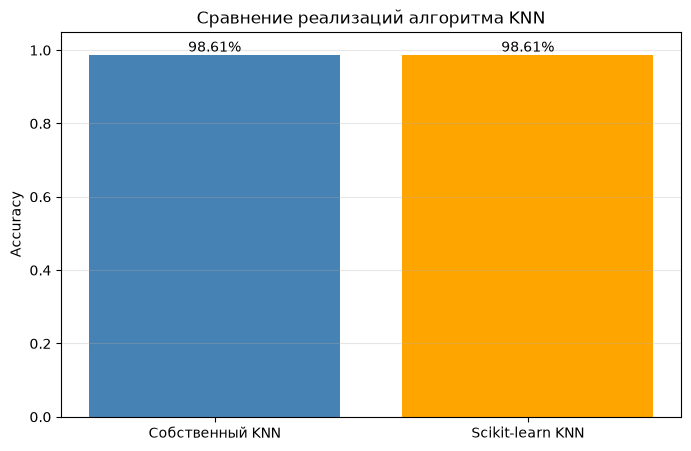

In [18]:
models = [
    "Собственный KNN",
    "Scikit-learn KNN"
]

accuracies = [
    test_accuracy,
    sklearn_accuracy
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    accuracies,
    color=["steelblue", "orange"]
)

plt.ylabel("Accuracy")

plt.title("Сравнение реализаций алгоритма KNN")

plt.ylim(0, 1.05)

plt.grid(axis="y", alpha=0.3)

for bar, accuracy in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{accuracy * 100:.2f}%",
        ha="center"
    )

plt.show()

### 9. Итоговые результаты

In [19]:
import pandas as pd

results = pd.DataFrame({
    "Характеристика": [
        "Количество изображений",
        "Количество классов",
        "Количество признаков",
        "Обучающие изображения",
        "Тестовые изображения",
        "Оптимальное k",
        "Accuracy собственного KNN",
        "Accuracy Scikit-learn"
    ],

    "Значение": [
        len(X),
        len(np.unique(y)),
        X.shape[1],
        len(X_train_val),
        len(X_test),
        best_k,
        f"{test_accuracy * 100:.2f}%",
        f"{sklearn_accuracy * 100:.2f}%"
    ]
})

display(results)

,Характеристика,Значение
0,Количество изображений,1797
1,Количество классов,10
2,Количество признаков,64
3,Обучающие изображения,1437
4,Тестовые изображения,360
5,Оптимальное k,2
6,Accuracy собственного KNN,98.61%
7,Accuracy Scikit-learn,98.61%


### 10. Вывод

В ходе лабораторной работы был изучен метод k ближайших соседей (KNN) и разработана программа классификации рукописных цифр на языке Python.

Для проведения экспериментов использовался набор данных Digits, содержащий 1797 изображений цифр от 0 до 9 размером 8×8 пикселей. Каждое изображение представлялось вектором из 64 признаков. Анализ распределения данных показал, что все классы представлены примерно одинаковым количеством изображений.

Была выполнена самостоятельная реализация алгоритма KNN, включающая вычисление евклидовых расстояний, поиск ближайших соседей и определение класса методом голосования.

В ходе исследования было изучено влияние количества ближайших соседей на точность классификации. Проверялись значения параметра k от 1 до 15. Наилучший результат на валидационной выборке был получен при **k = 2**, точность составила **98,61%**.

После выбора оптимального параметра была построена итоговая модель. На тестовой выборке из 360 изображений алгоритм правильно классифицировал 355 изображений, допустив всего 5 ошибок. Итоговая точность классификации составила **98,61%**.

Анализ матрицы ошибок и метрик Precision, Recall и F1-score показал, что модель успешно распознаёт большинство цифр. Классы 0, 2, 3, 5, 6 и 7 были классифицированы без ошибок. Наибольшие сложности возникли при распознавании цифр 8 и 9, что может объясняться визуальным сходством некоторых рукописных изображений.

Для проверки корректности разработанного алгоритма было выполнено сравнение с готовой реализацией KNeighborsClassifier из библиотеки Scikit-learn. Обе реализации продемонстрировали одинаковую точность — **98,61%**, а их предсказания совпали на 100%, что подтверждает корректность собственной реализации KNN на исследуемых данных.

Таким образом, метод k ближайших соседей показал высокую эффективность в задаче классификации рукописных цифр. Эксперимент продемонстрировал важность выбора параметра k и подтвердил, что даже относительно простой алгоритм машинного обучения способен обеспечивать высокую точность распознавания изображений.